# Tugas UTS: Linear Regression & Logistic Regression
**Mata Kuliah:** Machine Learning

Tugas ini menguji pemahaman Anda tentang materi **Simple Regression** (`simple_regression/regression_1.ipynb`) dan **Simple Classification** (`simple_classification/classification_1.ipynb`). Anda akan menerapkan algoritma yang sama pada **dataset baru**, lalu mengembangkannya dengan evaluasi dan eksperimen tambahan.

**Identitas Mahasiswa**
- Nama  : Siniar Wati Wau
- NIM   : 221011450523
- Kelas : Reg B

## 📌 Ketentuan Pengerjaan

1. Kerjakan semua soal di notebook ini pada sel kode / sel markdown yang telah disediakan.
2. **Model dan metrik evaluasi wajib diimplementasikan sendiri** dengan NumPy, seperti pada materi (`train_test_split`, `LinearRegression`, `LinearRegressionGD`, `LogisticRegression`, `accuracy_score`, `confusion_matrix`). Anda boleh menyalin implementasi dari materi.
   - Library yang boleh dipakai: `numpy`, `pandas`, `matplotlib`.
   - `scikit-learn` **tidak boleh** dipakai untuk model dan metrik, kecuali pada soal bonus untuk membandingkan hasil.
3. **`random_state` = 2 digit terakhir NIM Anda** (contoh: NIM `...0347` → `random_state=47`; jika `00`, gunakan `100`). Karena itu, setiap mahasiswa akan mendapat hasil angka yang berbeda.
4. Setiap soal yang meminta **penjelasan/analisis** dijawab dengan kalimat Anda sendiri pada sel markdown, dan harus merujuk ke angka/grafik hasil Anda.
5. Notebook harus **sudah dijalankan** (*Run All*) sehingga semua output dan grafik terlihat saat dibuka di GitHub.

## 📂 Dataset
Dataset disediakan di folder ini:

| File | Kolom | Keterangan |
|---|---|---|
| `Ads_Data.csv` | `BiayaIklan`, `Penjualan` | Biaya iklan per bulan (juta Rp) dan penjualan per bulan (juta Rp), 40 data |
| `Email_Data.csv` | `JumlahLink`, `KataPromo`, `Spam` | Jumlah link dan jumlah kata promosi dalam sebuah email, serta label Spam (1) / Bukan Spam (0), 60 data |

## 📤 Cara Pengumpulan

1. Buat **repositori baru** di akun GitHub Anda masing-masing dengan nama: `uts-machine-learning-<NIM>` (contoh: `uts-machine-learning-20230801047`).
2. Atur repositori menjadi **Public**.
3. Struktur repositori minimal:
   ```
   uts-machine-learning-<NIM>/
   ├── README.md            # Nama, NIM, Kelas, dan ringkasan hasil (R², akurasi, dll)
   ├── tugas_UTS.ipynb      # notebook ini, sudah dijalankan lengkap dengan output
   ├── Ads_Data.csv
   └── Email_Data.csv
   ```
4. Kumpulkan **link repositori GitHub** di halaman **UTS pada Mentari**.
5. Batas waktu pengumpulan (hari terakhir periode UTS):

| Kelas | Batas Pengumpulan |
|---|---|
| **Reg B** | **Jumat, 23 Oktober 2026, pukul 23:59 WIB** |
| **Reg C** | **Sabtu, 24 Oktober 2026, pukul 23:59 WIB** |

> ⚠️ Yang dinilai adalah **commit terakhir sebelum batas waktu**. Commit setelah batas waktu tidak akan dinilai. Pastikan link yang dikumpulkan bisa dibuka (repositori tidak *private*).

## 🧮 Penilaian

| Bagian | Bobot |
|---|---|
| Bagian A – Linear Regression | 35% |
| Bagian B – Logistic Regression | 40% |
| Bagian C – Pemahaman Konsep | 15% |
| Kerapihan repositori, README, dan notebook (output lengkap, kode rapi & diberi komentar) | 10% |
| Bonus – Perbandingan dengan scikit-learn | +5 |

In [4]:
# Import library
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Dua digit terakhir NIM: 23
RANDOM_STATE = 23

In [5]:
def train_test_split(X, y, test_size=0.2, random_state=42):
    """Membagi data secara acak tanpa scikit-learn."""
    X = np.asarray(X)
    y = np.asarray(y)
    rng = np.random.RandomState(random_state)
    indices = rng.permutation(len(X))
    n_test = int(np.ceil(len(X) * test_size))
    test_idx = indices[:n_test]
    train_idx = indices[n_test:]
    return X[train_idx], X[test_idx], y[train_idx], y[test_idx]

class LinearRegression:
    """Linear regression dengan normal equation."""
    def fit(self, X, y):
        X = np.asarray(X, dtype=float)
        y = np.asarray(y, dtype=float).reshape(-1, 1)
        Xb = np.c_[np.ones((len(X), 1)), X]
        theta = np.linalg.pinv(Xb.T @ Xb) @ Xb.T @ y
        self.intercept_ = float(theta[0, 0])
        self.coef_ = theta[1:, 0]
        return self
    def predict(self, X):
        X = np.asarray(X, dtype=float)
        return self.intercept_ + X @ self.coef_

class LinearRegressionGD:
    """Linear regression dengan gradient descent dan loss MSE."""
    def __init__(self, learning_rate=0.01, n_iterations=1000):
        self.learning_rate = learning_rate
        self.n_iterations = n_iterations
        self.loss_history = []
    def fit(self, X, y):
        X = np.asarray(X, dtype=float)
        y = np.asarray(y, dtype=float).reshape(-1)
        Xb = np.c_[np.ones((len(X), 1)), X]
        theta = np.zeros(Xb.shape[1])
        self.loss_history = []
        with np.errstate(over='ignore', invalid='ignore'):
            for _ in range(self.n_iterations):
                err = Xb @ theta - y
                self.loss_history.append(float(np.mean(err ** 2)))
                grad = (2 / len(X)) * (Xb.T @ err)
                theta -= self.learning_rate * grad
        self.intercept_ = float(theta[0])
        self.coef_ = theta[1:]
        return self
    def predict(self, X):
        return self.intercept_ + np.asarray(X, dtype=float) @ self.coef_

def mae(y_true, y_pred):
    return float(np.mean(np.abs(np.asarray(y_true) - np.asarray(y_pred))))
def mse(y_true, y_pred):
    return float(np.mean((np.asarray(y_true) - np.asarray(y_pred)) ** 2))
def rmse(y_true, y_pred):
    return float(np.sqrt(mse(y_true, y_pred)))
def r2_score(y_true, y_pred):
    y_true, y_pred = np.asarray(y_true), np.asarray(y_pred)
    ss_res = np.sum((y_true-y_pred)**2)
    ss_tot = np.sum((y_true-np.mean(y_true))**2)
    return float(1 - ss_res/ss_tot) if ss_tot != 0 else 0.0

def sigmoid(z):
    z = np.clip(np.asarray(z, dtype=float), -500, 500)
    return 1 / (1 + np.exp(-z))

class LogisticRegression:
    """Logistic regression biner dengan gradient descent."""
    def __init__(self, learning_rate=0.1, n_iterations=10000):
        self.learning_rate = learning_rate
        self.n_iterations = n_iterations
        self.loss_history = []
    def fit(self, X, y):
        X = np.asarray(X, dtype=float)
        y = np.asarray(y, dtype=float).reshape(-1)
        Xb = np.c_[np.ones((len(X), 1)), X]
        theta = np.zeros(Xb.shape[1])
        self.loss_history = []
        for _ in range(self.n_iterations):
            probs = sigmoid(Xb @ theta)
            eps = 1e-12
            loss = -np.mean(y*np.log(probs+eps) + (1-y)*np.log(1-probs+eps))
            self.loss_history.append(float(loss))
            grad = Xb.T @ (probs-y) / len(y)
            theta -= self.learning_rate * grad
        self.intercept_ = float(theta[0])
        self.coef_ = theta[1:]
        return self
    def predict_proba(self, X):
        X = np.asarray(X, dtype=float)
        Xb = np.c_[np.ones((len(X), 1)), X]
        p1 = sigmoid(Xb @ np.r_[self.intercept_, self.coef_])
        return np.c_[1-p1, p1]
    def predict(self, X, threshold=0.5):
        return (self.predict_proba(X)[:, 1] >= threshold).astype(int)

def confusion_matrix(y_true, y_pred):
    y_true, y_pred = np.asarray(y_true).astype(int), np.asarray(y_pred).astype(int)
    return np.array([[np.sum((y_true==0)&(y_pred==0)), np.sum((y_true==0)&(y_pred==1))],
                     [np.sum((y_true==1)&(y_pred==0)), np.sum((y_true==1)&(y_pred==1))]])
def accuracy_score(y_true, y_pred):
    return float(np.mean(np.asarray(y_true) == np.asarray(y_pred)))
def classification_metrics(y_true, y_pred):
    tn, fp, fn, tp = confusion_matrix(y_true, y_pred).ravel()
    precision = tp/(tp+fp) if tp+fp else 0.0
    recall = tp/(tp+fn) if tp+fn else 0.0
    f1 = 2*precision*recall/(precision+recall) if precision+recall else 0.0
    return {'Accuracy': accuracy_score(y_true, y_pred), 'TN': int(tn), 'FP': int(fp),
            'FN': int(fn), 'TP': int(tp), 'Precision': precision, 'Recall': recall, 'F1-score': f1}

---
# Bagian A – Linear Regression (35%)

Sebuah toko online ingin mengetahui pengaruh **biaya iklan** terhadap **penjualan** setiap bulan. Gunakan dataset `Ads_Data.csv`.

### Soal A1 – Load & Visualisasi Data
1. Baca `Ads_Data.csv` menggunakan pandas dan tampilkan 5 data pertama serta jumlah baris datanya.
2. Pisahkan `X` (`BiayaIklan`) dan `y` (`Penjualan`). Pastikan `X` berbentuk 2 dimensi `(n, 1)`.
3. Buat *scatter plot* `BiayaIklan` vs `Penjualan` (lengkap dengan judul dan label sumbu).

,BiayaIklan,Penjualan
0,0.8,34.3
1,0.9,38.8
2,1.0,33.2
3,1.3,36.0
4,1.7,51.3


Jumlah baris: 40
Shape X: (40, 1) | Shape y: (40,)


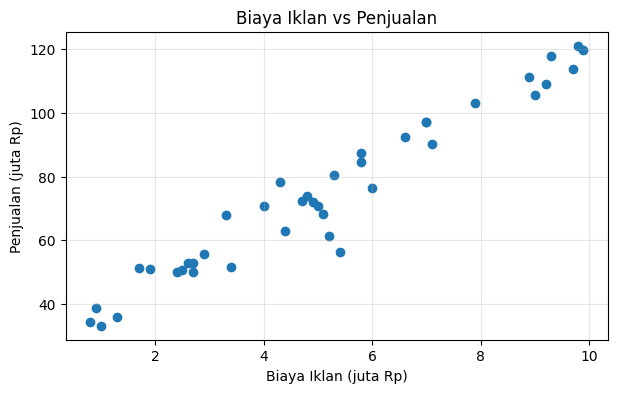

In [6]:
# A1: membaca data, menampilkan 5 baris, memisahkan X dan y
ads = pd.read_csv("Ads_Data.csv")
display(ads.head())
print("Jumlah baris:", len(ads))
X = ads[["BiayaIklan"]].to_numpy(dtype=float)
y = ads["Penjualan"].to_numpy(dtype=float)
print("Shape X:", X.shape, "| Shape y:", y.shape)

plt.figure(figsize=(7, 4))
plt.scatter(X[:, 0], y)
plt.title("Biaya Iklan vs Penjualan")
plt.xlabel("Biaya Iklan (juta Rp)")
plt.ylabel("Penjualan (juta Rp)")
plt.grid(alpha=0.3)
plt.show()

### Soal A2 – Split Data
Bagi data menjadi data training dan testing dengan `test_size=0.2` dan `random_state=RANDOM_STATE`. Tampilkan *shape* dari `X_train`, `X_test`, `y_train`, `y_test`.

In [7]:
# A2: split data 80% training dan 20% testing
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=RANDOM_STATE
)
print("X_train:", X_train.shape)
print("X_test :", X_test.shape)
print("y_train:", y_train.shape)
print("y_test :", y_test.shape)

X_train: (32, 1)
X_test : (8, 1)
y_train: (32,)
y_test : (8,)


### Soal A3 – Training dengan Normal Equation
1. Latih model `LinearRegression` (normal equation, seperti di materi) menggunakan data training.
2. Tampilkan nilai **intercept** ($b$) dan **koefisien** ($m$), lalu tuliskan persamaan garis regresinya: $\hat{y} = b + mX$.
3. **Interpretasikan** arti nilai $m$ dalam konteks kasus ini (misal: "setiap kenaikan biaya iklan 1 juta Rp, penjualan naik sebesar ...").

In [8]:
# A3: training dengan normal equation
lin_model = LinearRegression().fit(X_train, y_train)
print(f"Intercept (b): {lin_model.intercept_:.4f}")
print(f"Koefisien (m): {lin_model.coef_[0]:.4f}")
print(f"Persamaan regresi: ŷ = {lin_model.intercept_:.4f} + ({lin_model.coef_[0]:.4f} × X)")

Intercept (b): 28.9820
Koefisien (m): 9.0017
Persamaan regresi: ŷ = 28.9820 + (9.0017 × X)


**Jawaban A3 (interpretasi):** Koefisien menunjukkan perkiraan perubahan penjualan untuk setiap kenaikan biaya iklan Rp1 juta. Jika koefisien bernilai positif, penjualan diperkirakan meningkat sebesar nilai koefisien juta rupiah; jika negatif, penjualan diperkirakan menurun. Intercept adalah perkiraan penjualan saat biaya iklan bernilai 0 juta rupiah.

### Soal A4 – Evaluasi Model
Pada materi belum ada evaluasi untuk model regresi. **Implementasikan sendiri** fungsi-fungsi berikut menggunakan NumPy:

$$
MAE = \frac{1}{n}\sum_{i=1}^{n}|y_i - \hat{y}_i| \qquad
MSE = \frac{1}{n}\sum_{i=1}^{n}(y_i - \hat{y}_i)^2 \qquad
RMSE = \sqrt{MSE}
$$

$$
R^2 = 1 - \frac{\sum_{i=1}^{n}(y_i - \hat{y}_i)^2}{\sum_{i=1}^{n}(y_i - \bar{y})^2}
$$

1. Hitung MAE, MSE, RMSE, dan $R^2$ pada **data training** dan **data testing**.
2. Tampilkan hasilnya dalam satu tabel (boleh pakai `pd.DataFrame`).
3. Jelaskan arti nilai RMSE dan $R^2$ yang Anda dapatkan. Apakah model ini sudah baik?

In [9]:
# A4: evaluasi pada training dan testing
pred_train = lin_model.predict(X_train)
pred_test = lin_model.predict(X_test)
eval_reg = pd.DataFrame([
    {"Data": "Training", "MAE": mae(y_train, pred_train), "MSE": mse(y_train, pred_train),
     "RMSE": rmse(y_train, pred_train), "R²": r2_score(y_train, pred_train)},
    {"Data": "Testing", "MAE": mae(y_test, pred_test), "MSE": mse(y_test, pred_test),
     "RMSE": rmse(y_test, pred_test), "R²": r2_score(y_test, pred_test)}
])
display(eval_reg.round(4))

,Data,MAE,MSE,RMSE,R²
0,Training,4.7153,37.1852,6.0980,0.9422
1,Testing,3.8002,32.0786,5.6638,0.9455


**Jawaban A4 (analisis):** MAE adalah rata-rata besar kesalahan prediksi, sedangkan RMSE menunjukkan besar kesalahan dalam satuan penjualan dan memberi penalti lebih besar pada kesalahan besar. Nilai R² yang mendekati 1 menunjukkan model menjelaskan variasi data dengan baik; nilai mendekati 0 berarti kemampuan penjelasannya rendah. Bandingkan RMSE dan R² testing dengan training: hasil testing yang jauh lebih buruk menunjukkan kemampuan generalisasi kurang baik. Gunakan tabel di atas untuk menilai kualitas model pada dataset ini.

### Soal A5 – Gradient Descent & Learning Rate
1. Latih model `LinearRegressionGD` (dari materi) dengan `n_iterations=5000` menggunakan **3 nilai learning rate**: `0.001`, `0.02`, dan `0.1`.
2. Untuk setiap learning rate, tampilkan intercept dan koefisien akhirnya, lalu bandingkan dengan hasil normal equation (Soal A3).
3. Buat grafik **loss (MSE) vs iterasi** untuk ketiga learning rate (boleh dalam satu grafik atau *subplot*; gunakan skala log jika perlu).
4. Jelaskan apa yang terjadi pada masing-masing learning rate: mana yang **terlalu lambat**, mana yang **pas**, dan mana yang **gagal konvergen (divergen)**? Mengapa bisa terjadi?

> *Tips: jika muncul `RuntimeWarning: overflow`, itu adalah bagian dari hasil eksperimen. Jelaskan artinya.*

/usr/local/lib/python3.13/dist-packages/matplotlib/scale.py:253: RuntimeWarning: overflow encountered in power
  return np.power(self.base, values)


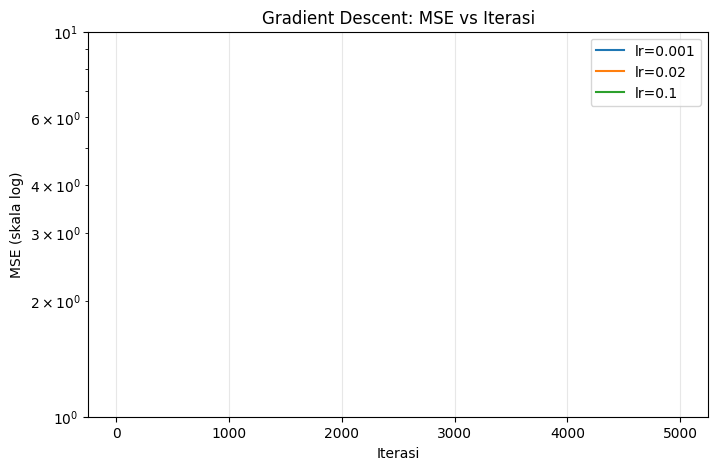

,Learning rate,Intercept,Koefisien,Loss akhir,Finite
0,0.001,25.92388,9.46995,39.27026,True
1,0.020,28.98203,9.00168,37.18520,True
2,0.100,NaN,NaN,NaN,False


Pembanding normal equation: b=28.9820, m=9.0017


In [10]:
# A5: eksperimen gradient descent dengan tiga learning rate
learning_rates = [0.001, 0.02, 0.1]
gd_models = {}
gd_rows = []
plt.figure(figsize=(8, 5))
for lr in learning_rates:
    model = LinearRegressionGD(learning_rate=lr, n_iterations=5000).fit(X_train, y_train)
    gd_models[lr] = model
    finite = np.isfinite(model.loss_history)
    final_loss = model.loss_history[-1]
    gd_rows.append({"Learning rate": lr, "Intercept": model.intercept_,
                    "Koefisien": model.coef_[0], "Loss akhir": final_loss,
                    "Finite": bool(np.all(finite))})
    hist = np.array(model.loss_history)
    hist[~np.isfinite(hist)] = np.nan
    plt.plot(hist, label=f"lr={lr}")
plt.yscale("log")
plt.title("Gradient Descent: MSE vs Iterasi")
plt.xlabel("Iterasi")
plt.ylabel("MSE (skala log)")
plt.legend()
plt.grid(alpha=0.3)
plt.show()
display(pd.DataFrame(gd_rows).round(5))
print(f"Pembanding normal equation: b={lin_model.intercept_:.4f}, m={lin_model.coef_[0]:.4f}")

**Jawaban A5 (analisis):** Learning rate 0.001 biasanya bergerak lebih lambat menuju nilai minimum. Learning rate 0.02 diharapkan lebih cepat dan stabil jika loss turun lalu mendatar serta koefisien mendekati hasil normal equation. Learning rate 0.1 dapat terlalu besar sehingga loss melonjak, menghasilkan `overflow`, atau tidak konvergen. Tentukan kesimpulan akhir berdasarkan grafik dan tabel yang muncul; jika loss menjadi `inf`/`nan`, berarti proses divergen karena langkah pembaruan terlalu besar.

### Soal A6 – Visualisasi & Prediksi
1. Buat grafik *scatter* data **testing** beserta **garis regresi** hasil model (Soal A3).
2. Prediksi penjualan jika biaya iklan sebesar **4.5 juta**, **7 juta**, dan **12 juta**.
3. Prediksi untuk 12 juta berada **di luar rentang data** (ekstrapolasi). Menurut Anda, seberapa bisa dipercaya hasil prediksi tersebut? Jelaskan.

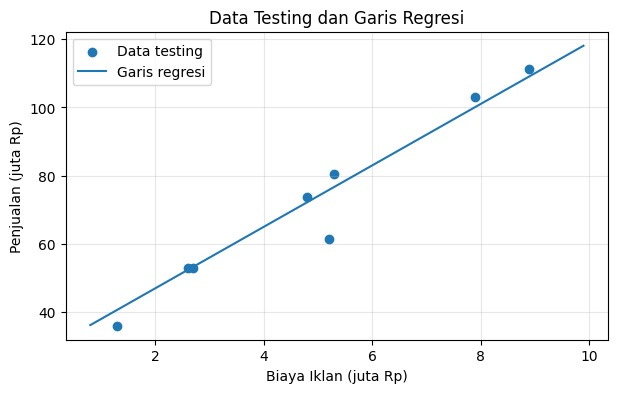

,BiayaIklan (juta Rp),PrediksiPenjualan (juta Rp)
0,4.5,69.490
1,7.0,91.994
2,12.0,137.002


In [11]:
# A6: visualisasi testing dengan garis regresi dan prediksi baru
plt.figure(figsize=(7, 4))
plt.scatter(X_test[:, 0], y_test, label="Data testing")
x_line = np.linspace(float(X.min()), float(X.max()), 100).reshape(-1, 1)
plt.plot(x_line[:, 0], lin_model.predict(x_line), label="Garis regresi")
plt.title("Data Testing dan Garis Regresi")
plt.xlabel("Biaya Iklan (juta Rp)")
plt.ylabel("Penjualan (juta Rp)")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

biaya_baru = np.array([[4.5], [7.0], [12.0]])
pred_baru = lin_model.predict(biaya_baru)
display(pd.DataFrame({"BiayaIklan (juta Rp)": biaya_baru[:,0],
                      "PrediksiPenjualan (juta Rp)": pred_baru}).round(3))

**Jawaban A6 (analisis):** Prediksi 4,5 dan 7 juta relatif lebih dapat dipercaya jika masih berada dalam rentang biaya iklan yang diamati. Prediksi untuk 12 juta merupakan ekstrapolasi karena melebihi rentang data (maksimum dataset 9,9 juta). Hasil ekstrapolasi lebih tidak pasti karena pola hubungan biaya iklan dan penjualan belum tentu tetap sama di luar data yang tersedia.

---
# Bagian B – Logistic Regression (40%)

Sebuah layanan email ingin membuat filter **spam** sederhana berdasarkan **jumlah link** dan **jumlah kata promosi** (misal: "gratis", "diskon", "promo") di dalam email. Gunakan dataset `Email_Data.csv`.

### Soal B1 – Load & Visualisasi Data
1. Baca `Email_Data.csv`, tampilkan 5 data pertama, dan hitung **jumlah email Spam dan Bukan Spam**.
2. Pisahkan `X` (`JumlahLink`, `KataPromo`) dan `y` (`Spam`).
3. Buat *scatter plot* `JumlahLink` vs `KataPromo` dengan warna berbeda untuk Spam dan Bukan Spam (lengkap dengan legend).

,JumlahLink,KataPromo,Spam
0,0,0,0
1,2,4,0
2,6,7,1
3,10,8,1
4,8,7,1


Jumlah kelas:


,Jumlah
Kelas,
Bukan Spam,35
Spam,25


Shape X: (60, 2) | Shape y: (60,)


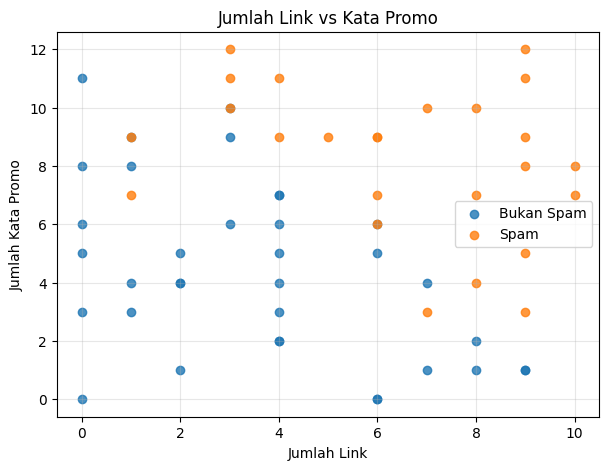

In [12]:
# B1: membaca data email dan melihat jumlah tiap kelas
emails = pd.read_csv("Email_Data.csv")
display(emails.head())
print("Jumlah kelas:")
display(emails["Spam"].map({0: "Bukan Spam", 1: "Spam"}).value_counts().rename_axis("Kelas").to_frame("Jumlah"))
X_email = emails[["JumlahLink", "KataPromo"]].to_numpy(dtype=float)
y_email = emails["Spam"].to_numpy(dtype=int)
print("Shape X:", X_email.shape, "| Shape y:", y_email.shape)

plt.figure(figsize=(7, 5))
for label, name in [(0, "Bukan Spam"), (1, "Spam")]:
    mask = y_email == label
    plt.scatter(X_email[mask, 0], X_email[mask, 1], label=name, alpha=0.8)
plt.title("Jumlah Link vs Kata Promo")
plt.xlabel("Jumlah Link")
plt.ylabel("Jumlah Kata Promo")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

### Soal B2 – Split Data & Training
1. Bagi data dengan `test_size=0.25` dan `random_state=RANDOM_STATE`.
2. Latih model `LogisticRegression` (gradient descent, dari materi) dengan `learning_rate=0.1` dan `n_iterations=10000`.
3. Tampilkan intercept ($b$) dan koefisien ($m_1, m_2$), lalu tuliskan persamaannya:
   $$P(\text{Spam}) = \sigma(b + m_1 \cdot \text{JumlahLink} + m_2 \cdot \text{KataPromo})$$
4. Buat grafik **log loss vs iterasi**. Apakah loss sudah turun dan stabil?

X_train: (45, 2) | X_test: (15, 2)
y_train: (45,) | y_test: (15,)
Intercept (b): -9.525250
Koefisien m1 (JumlahLink): 0.809980
Koefisien m2 (KataPromo): 0.924960
P(Spam) = sigmoid(-9.525250 + (0.809980 × JumlahLink) + (0.924960 × KataPromo))


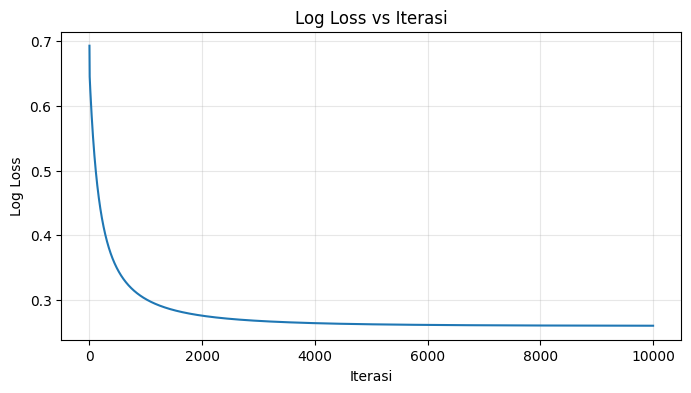

Loss awal: 0.693147
Loss akhir: 0.260212


In [13]:
# B2: split data, latih logistic regression dan tampilkan parameter
X_train_e, X_test_e, y_train_e, y_test_e = train_test_split(
    X_email, y_email, test_size=0.25, random_state=RANDOM_STATE
)
log_model = LogisticRegression(learning_rate=0.1, n_iterations=10000).fit(X_train_e, y_train_e)
print("X_train:", X_train_e.shape, "| X_test:", X_test_e.shape)
print("y_train:", y_train_e.shape, "| y_test:", y_test_e.shape)
print(f"Intercept (b): {log_model.intercept_:.6f}")
print(f"Koefisien m1 (JumlahLink): {log_model.coef_[0]:.6f}")
print(f"Koefisien m2 (KataPromo): {log_model.coef_[1]:.6f}")
print(f"P(Spam) = sigmoid({log_model.intercept_:.6f} + ({log_model.coef_[0]:.6f} × JumlahLink) + ({log_model.coef_[1]:.6f} × KataPromo))")
plt.figure(figsize=(8, 4))
plt.plot(log_model.loss_history)
plt.title("Log Loss vs Iterasi")
plt.xlabel("Iterasi")
plt.ylabel("Log Loss")
plt.grid(alpha=0.3)
plt.show()
print("Loss awal:", round(log_model.loss_history[0], 6))
print("Loss akhir:", round(log_model.loss_history[-1], 6))

**Jawaban B2 (analisis):** Model menghitung probabilitas email termasuk spam dari jumlah link dan kata promosi. Jika grafik log loss menurun lalu mendatar, model sedang belajar dan mulai stabil. Jika loss naik atau berosilasi kuat, laju pembelajaran mungkin terlalu besar. Koefisien positif meningkatkan log-odds spam ketika fitur tersebut bertambah, sedangkan koefisien negatif menurunkannya.

### Soal B3 – Evaluasi Model
Selain `accuracy_score` dan `confusion_matrix` dari materi, **implementasikan sendiri** fungsi berikut:

$$
Precision = \frac{TP}{TP + FP} \qquad
Recall = \frac{TP}{TP + FN} \qquad
F1 = 2 \cdot \frac{Precision \cdot Recall}{Precision + Recall}
$$

1. Hitung accuracy, confusion matrix, precision, recall, dan F1-score pada **data testing**.
2. Jelaskan arti nilai **FP** (*false positive*) dan **FN** (*false negative*) pada kasus filter spam. Kesalahan mana yang menurut Anda **lebih merugikan pengguna email**? Mengapa?

In [14]:
# B3: evaluasi klasifikasi pada data testing
y_pred_e = log_model.predict(X_test_e, threshold=0.5)
cm = confusion_matrix(y_test_e, y_pred_e)
print("Confusion matrix (baris aktual 0/1, kolom prediksi 0/1):")
print(cm)
metrics_test = classification_metrics(y_test_e, y_pred_e)
display(pd.DataFrame([metrics_test]).round(4))

Confusion matrix (baris aktual 0/1, kolom prediksi 0/1):
[[9 3]
 [0 3]]


,Accuracy,TN,FP,FN,TP,Precision,Recall,F1-score
0,0.8,9,3,0,3,0.5,1.0,0.6667


**Jawaban B3 (analisis):** FP adalah email bukan spam yang salah ditandai sebagai spam; email penting bisa masuk folder spam. FN adalah email spam yang salah dianggap bukan spam sehingga masuk kotak masuk. Kesalahan yang lebih merugikan bergantung pada kebutuhan pengguna. Untuk pengguna yang sering menerima email penting, FP bisa sangat merugikan karena pesan penting terlewat; untuk keamanan, FN juga berisiko karena pesan penipuan dapat lolos.

### Soal B4 – Decision Boundary
1. Hitung persamaan **decision boundary** (garis saat probabilitas = 0.5):
   $$b + m_1 x_1 + m_2 x_2 = 0 \;\Rightarrow\; x_2 = -\frac{b + m_1 x_1}{m_2}$$
2. Buat visualisasi data **testing** beserta *background* probabilitas (`contourf`) dan garis decision boundary, seperti di materi.
3. Tunjukkan (beri tanda/penjelasan) data testing mana saja yang **salah diklasifikasikan**.

Decision boundary: KataPromo = -(-9.525250 + (0.809980 × JumlahLink)) / (0.924960)
Atau x2 = -(-9.525250 + 0.809980 x1) / 0.924960


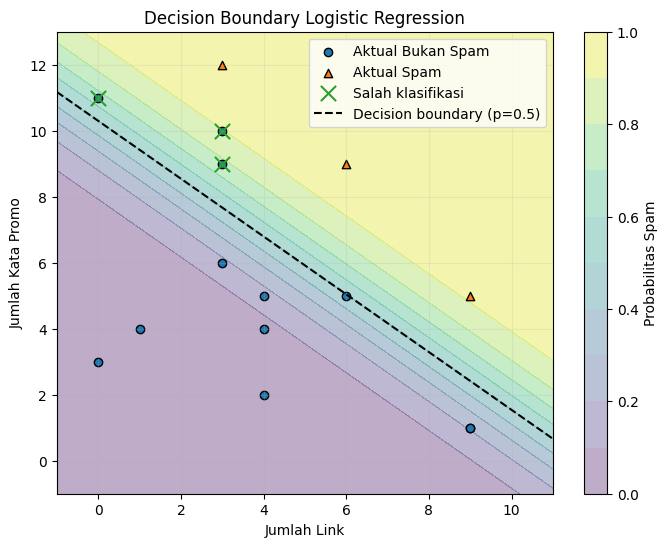

Data testing yang salah diklasifikasikan:


,JumlahLink,KataPromo,Aktual,Prediksi
0,3.0,10.0,0,1
1,3.0,9.0,0,1
2,0.0,11.0,0,1


In [15]:
# B4: decision boundary dan visualisasi probabilitas
b = log_model.intercept_
m1, m2 = log_model.coef_
if abs(m2) > 1e-12:
    print(f"Decision boundary: KataPromo = -({b:.6f} + ({m1:.6f} × JumlahLink)) / ({m2:.6f})")
    print(f"Atau x2 = -({b:.6f} + {m1:.6f} x1) / {m2:.6f}")
else:
    print("Koefisien KataPromo mendekati nol; decision boundary tidak dapat ditulis sebagai x2 = ... dengan stabil.")
x1_min, x1_max = X_email[:,0].min()-1, X_email[:,0].max()+1
x2_min, x2_max = X_email[:,1].min()-1, X_email[:,1].max()+1
xx, yy = np.meshgrid(np.linspace(x1_min, x1_max, 200), np.linspace(x2_min, x2_max, 200))
grid = np.c_[xx.ravel(), yy.ravel()]
prob = log_model.predict_proba(grid)[:,1].reshape(xx.shape)
plt.figure(figsize=(8, 6))
plt.contourf(xx, yy, prob, levels=np.linspace(0,1,11), alpha=0.35)
plt.colorbar(label="Probabilitas Spam")
for label, name, marker in [(0, "Bukan Spam", "o"), (1, "Spam", "^")]:
    mask = y_test_e == label
    plt.scatter(X_test_e[mask,0], X_test_e[mask,1], marker=marker, label=f"Aktual {name}", edgecolors="black")
wrong = y_pred_e != y_test_e
plt.scatter(X_test_e[wrong,0], X_test_e[wrong,1], marker="x", s=120, label="Salah klasifikasi")
if abs(m2) > 1e-12:
    xline = np.linspace(x1_min, x1_max, 200)
    yline = -(b + m1*xline)/m2
    plt.plot(xline, yline, "k--", label="Decision boundary (p=0.5)")
plt.title("Decision Boundary Logistic Regression")
plt.xlabel("Jumlah Link")
plt.ylabel("Jumlah Kata Promo")
plt.legend()
plt.grid(alpha=0.2)
plt.show()
wrong_df = pd.DataFrame({"JumlahLink": X_test_e[wrong,0], "KataPromo": X_test_e[wrong,1],
                         "Aktual": y_test_e[wrong], "Prediksi": y_pred_e[wrong]})
print("Data testing yang salah diklasifikasikan:")
display(wrong_df if len(wrong_df) else pd.DataFrame(columns=["JumlahLink","KataPromo","Aktual","Prediksi"]))

**Jawaban B4 (analisis):** Decision boundary adalah garis dengan probabilitas spam 0,5. Titik di sisi dengan probabilitas ≥ 0,5 diprediksi spam, sedangkan titik di sisi lainnya diprediksi bukan spam. Pada grafik, tanda silang menunjukkan data testing yang salah diklasifikasikan.

### Soal B5 – Eksperimen Threshold
Secara default, model memprediksi Spam jika $P(\text{Spam}) \geq 0.5$.

1. Gunakan `predict_proba` lalu buat prediksi dengan threshold **0.3**, **0.5**, dan **0.7**.
2. Untuk setiap threshold, hitung confusion matrix, precision, dan recall. Tampilkan dalam satu tabel.
3. Jelaskan pengaruh menaikkan/menurunkan threshold terhadap precision dan recall. Berdasarkan jawaban Anda di Soal B3, **threshold mana yang Anda pilih** untuk filter spam? Beri alasan.

In [16]:
# B5: evaluasi beberapa threshold
threshold_rows = []
for threshold in [0.3, 0.5, 0.7]:
    pred = log_model.predict(X_test_e, threshold=threshold)
    met = classification_metrics(y_test_e, pred)
    threshold_rows.append({"Threshold": threshold, "Confusion Matrix": str(confusion_matrix(y_test_e, pred).tolist()),
                           "Precision": met["Precision"], "Recall": met["Recall"],
                           "FP": met["FP"], "FN": met["FN"]})
threshold_table = pd.DataFrame(threshold_rows)
display(threshold_table.round(4))

,Threshold,Confusion Matrix,Precision,Recall,FP,FN
0,0.3,"[[8, 4], [0, 3]]",0.4286,1.0,4,0
1,0.5,"[[9, 3], [0, 3]]",0.5000,1.0,3,0
2,0.7,"[[10, 2], [0, 3]]",0.6000,1.0,2,0


**Jawaban B5 (analisis):** Threshold lebih rendah membuat model lebih mudah menyebut email sebagai spam, biasanya meningkatkan recall tetapi juga dapat menambah FP dan menurunkan precision. Threshold lebih tinggi membuat prediksi spam lebih ketat, biasanya mengurangi FP tetapi dapat menambah FN. Pilih threshold sesuai prioritas: jika email penting tidak boleh masuk folder spam, gunakan threshold lebih tinggi; jika ingin menangkap sebanyak mungkin spam, threshold lebih rendah dapat dipertimbangkan. Sesuaikan keputusan dengan tabel hasil pengujian.

### Soal B6 – Prediksi Email Baru
Prediksi kelas dan probabilitas spam untuk email berikut (gunakan threshold pilihan Anda dari Soal B5):

| Email | JumlahLink | KataPromo |
|---|---|---|
| E1 | 1 | 2 |
| E2 | 5 | 6 |
| E3 | 9 | 10 |
| E4 | 2 | 11 |

In [17]:
# B6: prediksi empat email baru memakai threshold pilihan
PILIHAN_THRESHOLD = 0.5  # dapat diubah sesuai kesimpulan B5
email_baru = pd.DataFrame({
    "Email": ["E1", "E2", "E3", "E4"],
    "JumlahLink": [1, 5, 9, 2],
    "KataPromo": [2, 6, 10, 11]
})
X_baru = email_baru[["JumlahLink", "KataPromo"]].to_numpy(dtype=float)
prob_spam = log_model.predict_proba(X_baru)[:,1]
pred_spam = (prob_spam >= PILIHAN_THRESHOLD).astype(int)
email_baru["Probabilitas Spam"] = prob_spam
email_baru["Prediksi"] = np.where(pred_spam == 1, "Spam", "Bukan Spam")
email_baru["Threshold"] = PILIHAN_THRESHOLD
display(email_baru.round(4))

,Email,JumlahLink,KataPromo,Probabilitas Spam,Prediksi,Threshold
0,E1,1,2,0.0010,Bukan Spam,0.5
1,E2,5,6,0.5186,Spam,0.5
2,E3,9,10,0.9991,Spam,0.5
3,E4,2,11,0.9063,Spam,0.5


---
# Bagian C – Pemahaman Konsep (15%)

Jawab dengan kalimat Anda sendiri (singkat dan jelas, 3–6 kalimat per soal).

1. Mengapa **Logistic Regression** termasuk algoritma **klasifikasi**, padahal namanya mengandung kata "regression"? Apa peran fungsi **sigmoid**?
2. Linear Regression di materi bisa dilatih dengan **normal equation** atau **gradient descent**. Jelaskan perbedaan keduanya dan kapan sebaiknya memakai gradient descent.
3. Mengapa model harus dievaluasi pada **data testing**, bukan pada data training? Apa yang dimaksud dengan **overfitting**?
4. Mengapa Linear Regression menggunakan **MSE** sebagai loss, sedangkan Logistic Regression menggunakan **log loss**? (Petunjuk: perhatikan jenis output masing-masing model.)
5. Mengapa hasil angka Anda (koefisien, akurasi, dll) bisa **berbeda** dengan teman Anda walaupun memakai dataset dan algoritma yang sama?

**Jawaban C1:** Logistic Regression termasuk klasifikasi karena hasil akhirnya berupa kelas, misalnya spam atau bukan spam. Model menghitung skor dari fitur, lalu fungsi sigmoid mengubah skor itu menjadi probabilitas antara 0 dan 1. Probabilitas tersebut dibandingkan dengan threshold untuk menentukan kelas.

**Jawaban C2:** Normal equation menghitung parameter secara langsung melalui operasi matriks dan tidak memerlukan iterasi. Gradient descent memperbarui parameter sedikit demi sedikit berdasarkan gradien loss. Gradient descent lebih cocok untuk data besar atau ketika perhitungan langsung matriks menjadi berat, tetapi learning rate harus dipilih dengan tepat.

**Jawaban C3:** Data testing digunakan untuk menilai kemampuan model pada data yang tidak dipakai saat pelatihan. Jika hanya menguji data training, hasil bisa terlihat bagus tetapi belum tentu bekerja pada data baru. Overfitting adalah kondisi ketika model terlalu menyesuaikan diri dengan data training sehingga performanya menurun pada data baru.

**Jawaban C4:** Linear Regression menghasilkan nilai kontinu, sehingga MSE mengukur rata-rata kuadrat selisih prediksi dengan nilai sebenarnya. Logistic Regression menghasilkan probabilitas kelas, sehingga log loss mengukur seberapa baik probabilitas tersebut sesuai dengan label sebenarnya. Log loss memberi hukuman besar ketika model sangat yakin tetapi prediksinya salah.

**Jawaban C5:** Hasil dapat berbeda karena pembagian data training dan testing dapat berbeda ketika random state berbeda. Parameter yang dipelajari juga dipengaruhi jumlah data, urutan pembaruan, learning rate, jumlah iterasi, dan inisialisasi. Pada tugas ini, random state ditentukan dari dua digit terakhir NIM agar hasil setiap mahasiswa dapat berbeda.

---
# Bonus (+5) – Perbandingan dengan scikit-learn

Latih ulang kedua model menggunakan `sklearn.linear_model.LinearRegression` dan `sklearn.linear_model.LogisticRegression` dengan data training yang **sama**. Bandingkan koefisien dan hasil evaluasinya dengan implementasi Anda. Jika ada perbedaan (terutama pada Logistic Regression), jelaskan penyebabnya.

> *Petunjuk: baca dokumentasi parameter `penalty` / `C` pada `LogisticRegression` scikit-learn.*

In [18]:
# BONUS: perbandingan dengan scikit-learn (hanya untuk bagian bonus)
try:
    from sklearn.linear_model import LinearRegression as SkLinearRegression
    from sklearn.linear_model import LogisticRegression as SkLogisticRegression
    from sklearn.metrics import mean_squared_error, accuracy_score as sk_accuracy

    sk_lin = SkLinearRegression().fit(X_train, y_train)
    sk_lin_pred = sk_lin.predict(X_test)
    print("Linear Regression")
    print(f"Implementasi sendiri: intercept={lin_model.intercept_:.5f}, coef={lin_model.coef_[0]:.5f}, RMSE={rmse(y_test, pred_test):.5f}, R²={r2_score(y_test, pred_test):.5f}")
    print(f"scikit-learn        : intercept={sk_lin.intercept_:.5f}, coef={sk_lin.coef_[0]:.5f}, RMSE={np.sqrt(mean_squared_error(y_test, sk_lin_pred)):.5f}, R²={r2_score(y_test, sk_lin_pred):.5f}")

    sk_log = SkLogisticRegression(max_iter=10000).fit(X_train_e, y_train_e)
    sk_pred = sk_log.predict(X_test_e)
    print("\nLogistic Regression")
    print(f"Implementasi sendiri: b={log_model.intercept_:.5f}, coef={log_model.coef_}, accuracy={accuracy_score(y_test_e, y_pred_e):.5f}")
    print(f"scikit-learn        : b={sk_log.intercept_[0]:.5f}, coef={sk_log.coef_[0]}, accuracy={sk_accuracy(y_test_e, sk_pred):.5f}")
except Exception as e:
    print("Bagian bonus tidak dapat dijalankan pada lingkungan ini:", repr(e))

Linear Regression
Implementasi sendiri: intercept=28.98203, coef=9.00168, RMSE=5.66380, R²=0.94552
scikit-learn        : intercept=28.98203, coef=9.00168, RMSE=5.66380, R²=0.94552

Logistic Regression
Implementasi sendiri: b=-9.52525, coef=[0.8099803  0.92496033], accuracy=0.80000
scikit-learn        : b=-8.69910, coef=[0.7361521  0.84447627], accuracy=0.80000


**Jawaban Bonus (analisis):** Hasil Linear Regression dengan normal equation seharusnya sangat dekat dengan scikit-learn karena keduanya meminimalkan jumlah kuadrat error. Logistic Regression dapat berbeda karena scikit-learn secara default menggunakan regularisasi L2, sedangkan implementasi gradient descent di atas tidak memakai regularisasi. Perbedaan solver, toleransi konvergensi, dan jumlah iterasi juga dapat memengaruhi koefisien.